# Eta Car light curves: explore, fit, and compare
Run cells in order. In VS Code choose the **light_echo** Python environment and enable the Jupyter extension. Widgets require a running kernel; saved plots below remain readable without one. No sampling runs unless you explicitly set `RUN_FIT = True`.

We model three intrinsic Bazin peaks, smooth their sum with a Gaussian, and add a separately estimated background. Historical comparisons are illustrative: the historical bandpass differs from g.

**Starting point:** maximum-likelihood sample in the saved Notebook 6 Dynesty result (42,642 samples). The saved posterior agrees with its printed medians; earlier predictive figures had inconsistent execution states. All views here use the same parameter vector. Numerical convolution is corrected to a fixed, padded uniform grid; inherited parameters are therefore a reference, not a newly optimized fit under the corrected implementation.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import fftconvolve
from scipy.optimize import least_squares
import ipywidgets as widgets
from IPython.display import display, clear_output
BASE = next((p for p in (Path.cwd(), Path.cwd()/'eta_car_lc_interactive') if (p/'baseline.json').is_file()), None)
if BASE is None: raise FileNotFoundError('Open this notebook from the eta_car_lc_interactive folder.')
meta = json.loads((BASE/'baseline.json').read_text())
NAMES = list(meta['parameters']); BASELINE = np.array(list(meta['parameters'].values()))
plt.rcParams.update({'figure.dpi':100, 'axes.grid':True, 'grid.alpha':.2})
display(pd.DataFrame({'parameter':NAMES, 'baseline':BASELINE, 'unit':['normalized flux' if n.startswith('A') else 'year' for n in NAMES]}))
print(meta['summary'])

,parameter,baseline,unit
0,A1,0.327224,normalized flux
1,t0_1,1837.540785,year
2,tau_rise_1,0.000257,year
3,tau_fall_1,0.515540,year
4,A2,0.488275,normalized flux
5,t0_2,1842.853562,year
6,tau_rise_2,0.000442,year
7,tau_fall_2,0.525105,year
8,A3,2.185310,normalized flux
9,t0_3,1844.779261,year


Maximum stored log-likelihood sample from Notebook 6 result; not a new fit


## 1. Model and numerical smoothing
For one peak, $F(t)=A/[e^{(t-t_0)/\tau_f}+e^{(t-t_0)(1/\tau_f-1/\tau_r)}]$.

- **A** scales brightness; it is not generally the maximum flux.
- **t0** is a reference time, not generally the peak time.
- **tau_rise / tau_fall** control the rise and decay. We require rise < fall for a transient peak.
- **sigma** is the Gaussian standard deviation in years. Larger values broaden and lower peaks. A normalized kernel conserves integrated flux over a sufficiently wide interval.

The background is added **after** smoothing the transient peaks. A fixed padded grid makes predictions independent of zoom and observation spacing. Sharp rises are integrated on an adaptive local grid before smoothing, avoiding aliasing.

In [2]:
from scipy.integrate import cumulative_trapezoid
from scipy.special import expit
GRID = np.arange(1820., 1880.0001, .002)
DT = GRID[1]-GRID[0]
def bazin(t,A,t0,rise,fall):
    if rise <= 0 or fall <= rise: raise ValueError('Require 0 < rise < fall')
    x = np.asarray(t)-t0
    return A*np.exp(-np.logaddexp(x/fall, x*(1/fall-1/rise)))
def components(t,p):
    return np.array([bazin(t,*p[k:k+4]) for k in (0,4,8)])
def intrinsic(t,p): return components(t,p).sum(axis=0)
def convolved(t,p):
    sigma=p[12]
    if sigma == 0: return intrinsic(t,p)
    # Cell-average the sharp intrinsic peaks, resolving their rise locally.
    edges=np.r_[GRID-DT/2,GRID[-1]+DT/2]
    extras=[]
    for k in (0,4,8):
        t0,rise=p[k+1:k+3]
        extras.append(t0+np.linspace(-30*rise,30*rise,601))
    #fine=np.unique(np.r_[edges, *extras])
    fine = np.unique(np.concatenate([edges, *extras]))
    fine=fine[(fine>=edges[0])&(fine<=edges[-1])]
    integral=cumulative_trapezoid(intrinsic(fine,p),fine,initial=0)
    averaged=np.diff(np.interp(edges,fine,integral))/DT
    offsets=np.arange(-int(np.ceil(6*sigma/DT)),int(np.ceil(6*sigma/DT))+1)*DT
    kernel=np.exp(-.5*(offsets/sigma)**2);kernel/=kernel.sum()
    return np.interp(t,GRID,fftconvolve(averaged,kernel,mode='same'))


## 2. Try one peak
Change a control and release the slider to redraw. Blue is intrinsic; red is smoothed. No fit is performed. Static default views are also saved below the controls.

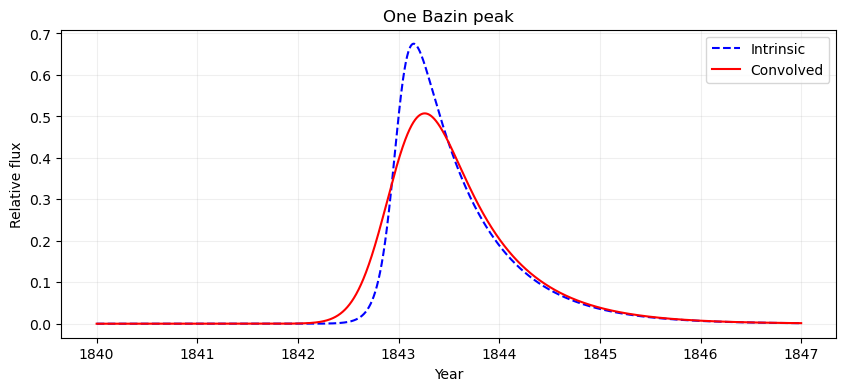

In [3]:
def control(value, label, lo, hi, log=False):
    common=dict(value=float(value),description=label,continuous_update=False,style={'description_width':'105px'},layout=widgets.Layout(width='320px'))
    if log: return widgets.FloatLogSlider(base=10,min=np.log10(lo),max=np.log10(hi),step=.05,readout_format='.4g',**common)
    return widgets.FloatSlider(min=lo,max=hi,step=(hi-lo)/400,readout_format='.4f',**common)
def widget_panel(controls, callback, defaults, extra=()):
    out=widgets.Output(); reset=widgets.Button(description='Reset to baseline')
    def update(change=None):
        with out:
            clear_output(wait=True)
            try: callback(**{k:v.value for k,v in controls.items()})
            except ValueError as e: print(str(e))
    for w in controls.values(): w.observe(update,names='value')
    def restore(button):
        for k,v in defaults.items(): controls[k].value=float(v) if isinstance(v,(int,float,np.number)) and not isinstance(v,bool) else v
    reset.on_click(restore)
    if all(name in controls for name in NAMES[:12]):
        columns=[]
        for i in range(3):
            keys=NAMES[4*i:4*i+4]
            columns.append(widgets.VBox([widgets.HTML(f'<b>Peak {i+1}</b>'),*[controls[k] for k in keys]],layout=widgets.Layout(min_width='320px')))
        other=[w for k,w in controls.items() if k not in NAMES[:12]]
        columns.append(widgets.VBox([widgets.HTML('<b>Smoothing, alignment & views</b>'),*other,
            widgets.HTML('<small>History scale multiplies the entire intrinsic model + background.<br>History shift moves that model in years; positive = later.<br>Neither changes the echo data or the historical points.</small>')],layout=widgets.Layout(min_width='320px',max_width='340px')))
        panel=widgets.Box(columns,layout=widgets.Layout(display='flex',flex_flow='row nowrap',overflow='auto',width='100%',gap='12px'))
    else:
        panel=widgets.HBox([widgets.VBox(list(controls.values())[:5]),widgets.VBox(list(controls.values())[5:])])
    display(widgets.VBox([*extra,panel,reset,out]))
    update()
    return controls,update
single_defaults=dict(A=1.,t0=1843.,rise=.08,fall=.6,sigma=.24)
def plot_single(A,t0,rise,fall,sigma):
    p=np.array([A,t0,rise,fall,0,1837,.001,.5,0,1845,.05,.3,sigma])
    t=np.linspace(1840,1847,3500)
    fig,ax=plt.subplots(figsize=(10,4));ax.plot(t,intrinsic(t,p),'b--',label='Intrinsic');ax.plot(t,convolved(t,p),'r',label='Convolved')
    ax.set(xlabel='Year',ylabel='Relative flux',title='One Bazin peak');ax.legend();plt.show();plt.close(fig)
single_controls={k:control(v,k,*limits,log=k in ['rise','fall']) for (k,v),limits in zip(single_defaults.items(),[(0,3),(1841,1845),(.0001,.5),(.51,3),(0,1)])}
single_ui=widget_panel(single_controls,plot_single,single_defaults)
plot_single(**single_defaults)

## 3. Data and background
We use the phase-calibrated g-band table, with year = 1845 + phase/365.25, and normalize by its maximum. Following Notebook 6, an **unweighted cubic** background is fitted over 1835–1849, excluding 1837–1840 and 1842.5–1846. The original comment called it weighted, but its executed code was unweighted. Centering the polynomial improves numerical conditioning.

Background uncertainty is not propagated, and the dense input table can have correlated points. Formal uncertainties and reduced chi-square must be interpreted under these assumptions. The background is never extrapolated across the historical record.

In [13]:
lcpath = '../emcee_fitting/LC_tables/models/'

#lcpath = './emcee_fitting/LC_tables/models/seperate_fit/' # path mcmc fit seperatelatey each bands, keep tshift same

# new model using MCMC
LCm2_i = pd.read_csv(lcpath +'iLC_mod2.csv')
LCm2_g = pd.read_csv(lcpath +'gLC_mod2.csv')
LCm2_r = pd.read_csv(lcpath +'rLC_mod2.csv')
LCm2_z = pd.read_csv(lcpath +'zLC_mod2.csv')

LCdat2_i = pd.read_csv(lcpath +'iLC_data2.csv')
LCdat2_g = pd.read_csv(lcpath +'gLC_data2.csv')
LCdat2_r = pd.read_csv(lcpath +'rLC_data2.csv')
LCdat2_z = pd.read_csv(lcpath +'zLC_data2.csv')


In [24]:
LCm2_g.mjd, LCm2_r.mjd

(0       53044.369999
 1       53046.889893
 2       53049.409788
 3       53051.929683
 4       53054.449578
             ...     
 4995    65631.244631
 4996    65633.764526
 4997    65636.284421
 4998    65638.804315
 4999    65641.324210
 Name: mjd, Length: 5000, dtype: float64,
 0       53044.374475
 1       53046.894968
 2       53049.415461
 3       53051.935954
 4       53054.456447
             ...     
 4995    65634.236955
 4996    65636.757448
 4997    65639.277941
 4998    65641.798434
 4999    65644.318927
 Name: mjd, Length: 5000, dtype: float64)

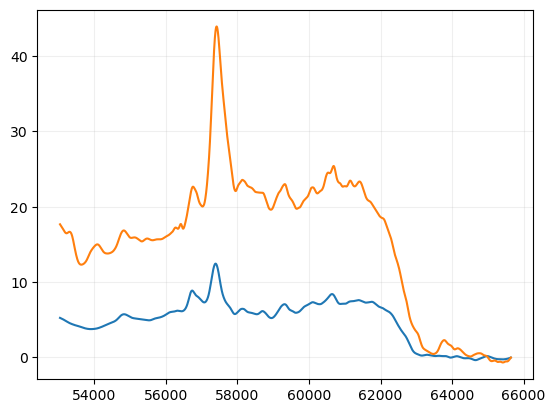

In [23]:


x = LCm2_g.mjd
y = LCm2_g.muJyas2

plt.plot(x, y)

x = LCm2_r.mjd
y = LCm2_r.muJyas2

plt.plot(x, y)


plt.plot()

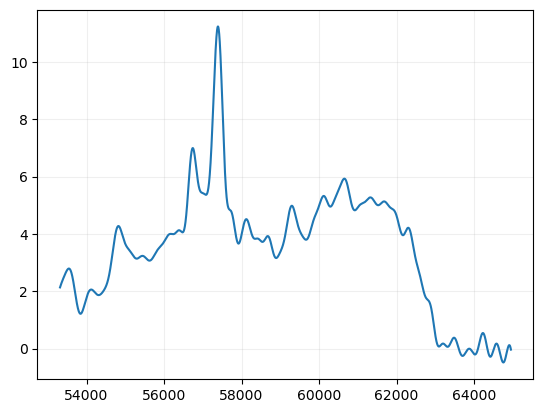

In [18]:
x = data.mjd
y = data.mJyas2

plt.plot(x, y)

### filters 

In [30]:
decam_g

,3815 0.00054
0,3820 0.0006
1,3825 0.0006
2,3830 0.0006
3,3835 0.0007
4,3840 0.00079
...,...
349,5565 0.00085
350,5570 0.00075
351,5575 0.00065
352,5580 0.00055


In [40]:
decam_g = pd.read_csv("../data/filters/decam/decam_g.dat", header=None, sep=' ',names=['wavelength', 'transmission',])


generic_V = pd.read_csv("../data/filters/generic/Generic_Bessell.V.dat", sep=' ', header=None, names=['wavelength', 'transmission'])



In [41]:
decam_g

,wavelength,transmission
0,3815,0.00054
1,3820,0.00060
2,3825,0.00060
3,3830,0.00060
4,3835,0.00070
...,...,...
350,5565,0.00085
351,5570,0.00075
352,5575,0.00065
353,5580,0.00055


In [42]:
generic_V

,wavelength,transmission
0,4700.0,0.000
1,4800.0,0.030
2,4900.0,0.163
3,5000.0,0.458
4,5100.0,0.780
5,5200.0,0.967
6,5300.0,1.000
7,5400.0,0.973
8,5500.0,0.898
9,5600.0,0.792


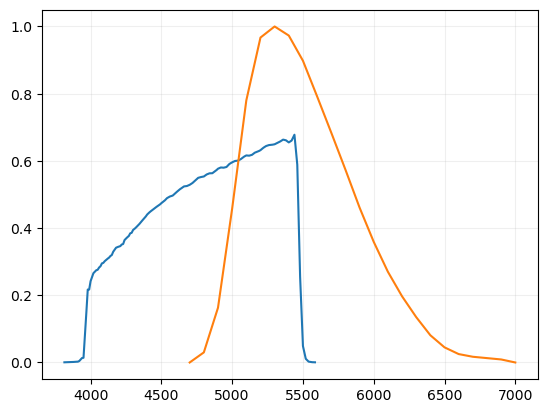

In [44]:
plt.plot(decam_g.wavelength, decam_g.transmission)
plt.plot(generic_V.wavelength, generic_V.transmission)

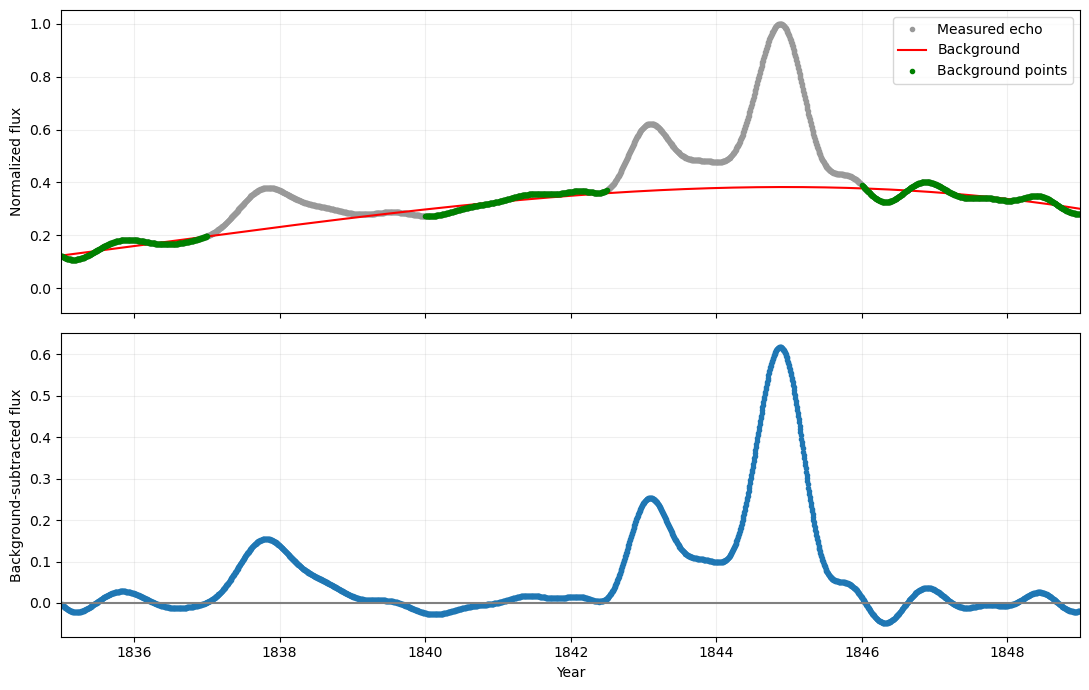

In [4]:
data=pd.read_csv(BASE/'echo_g.csv')
t=1845+data.phase.to_numpy()/365.25
flux=data.mJyas2.to_numpy()/data.mJyas2.max()
err=data.mJyas2_err.to_numpy()/data.mJyas2.max()
err=np.where(np.isfinite(err)&(err>0),err,np.nanmedian(err[err>0]))
fit_mask=(t>=1835)&(t<=1849)
bg_mask=fit_mask & ~((t>=1837)&(t<=1840)) & ~((t>=1842.5)&(t<=1846))
bg_coef=np.polyfit(t[bg_mask]-1843,flux[bg_mask],3)
def background(x): return np.polyval(bg_coef,np.asarray(x)-1843)
tf,yf,ef=t[fit_mask],flux[fit_mask],err[fit_mask]
fig,axs=plt.subplots(2,1,figsize=(11,7),sharex=True)
axs[0].plot(t,flux,'.',color='.6',label='Measured echo');axs[0].plot(tf,background(tf),'r',label='Background')
axs[0].plot(t[bg_mask],flux[bg_mask],'.',color='green',label='Background points');axs[0].legend();axs[0].set_ylabel('Normalized flux')
axs[1].plot(tf,yf-background(tf),'.');axs[1].axhline(0,color='.5');axs[1].set(xlabel='Year',ylabel='Background-subtracted flux',xlim=(1835,1849))
plt.tight_layout();plt.show();plt.close(fig)

## 4. Explore all three peaks against the measured echo
All 12 peak parameters and the common smoothing width are editable. Both model curves have the same fitted background restored. Reset returns to the stored maximum-likelihood sample. These exploratory changes never modify saved fit parameters. The data and model are restricted to the supported fitting interval.

The combined dashboard appears immediately below after both datasets are loaded. Its shared peak controls update both the echo and historical views together.

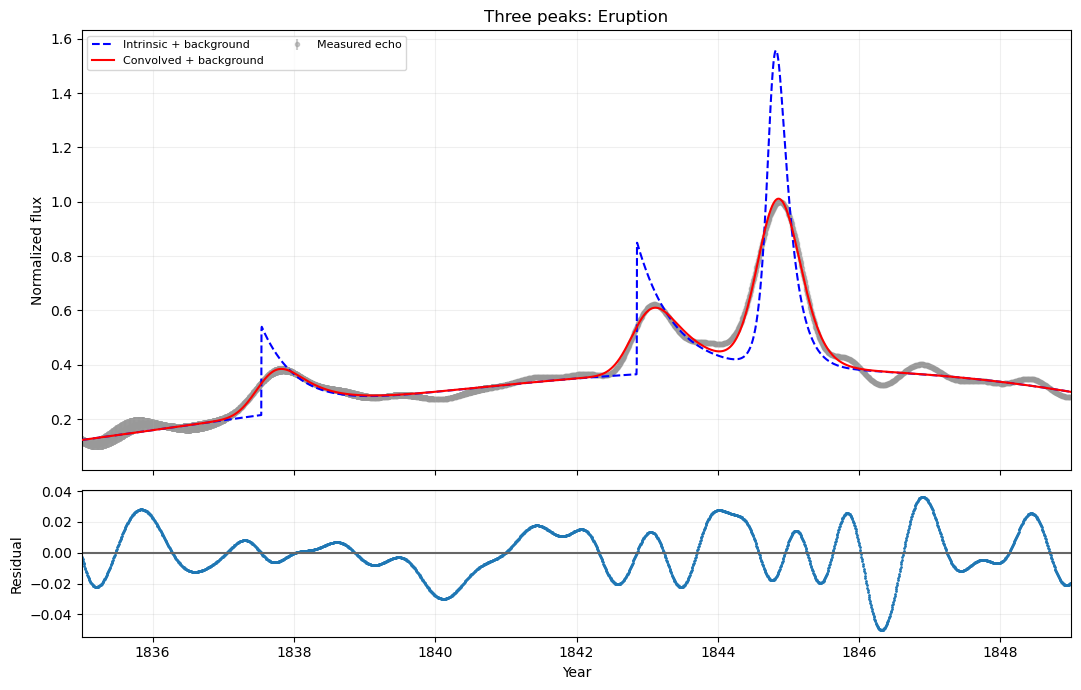

In [5]:
WINDOWS={'Eruption':(1835,1849),'Peak 1':(1836.5,1841),'Peak 2':(1841,1844.2),'Peak 3':(1843.5,1848)}
def peak_controls():
    cs={}
    for i in range(3):
        k=4*i
        for j,(lo,hi,log) in enumerate([(0,5,False),([1837,1841,1844][i],[1840,1843.5,1847][i],False),(.0001,.3,True),(.31,3,True)]):
            # Fall sliders include shorter baseline decays.
            if j==3: lo=.1
            cs[NAMES[k+j]]=control(BASELINE[k+j],NAMES[k+j],lo,hi,log)
    return cs
def plot_echo(p,view='Eruption',individual=True):
    x=np.linspace(1835,1849,4000);pred=convolved(tf,p)+background(tf)
    fig,axs=plt.subplots(2,1,figsize=(11,7),sharex=True,gridspec_kw={'height_ratios':[3,1]})
    axs[0].errorbar(tf,yf,yerr=ef,fmt='.',color='.6',alpha=.5,zorder=1,label='Measured echo')
    axs[0].plot(x,intrinsic(x,p)+background(x),'b--',zorder=3,label='Intrinsic + background')
    axs[0].plot(x,convolved(x,p)+background(x),'r',zorder=10,label='Convolved + background')
    if individual:
        for i,c in enumerate(components(x,p)): axs[0].plot(x,c,alpha=.5,lw=1,label=f'Intrinsic peak {i+1} (without background)')
    axs[0].set_ylabel('Normalized flux');axs[0].legend(fontsize=8,ncol=2)
    axs[1].plot(tf,yf-pred,'.',ms=2);axs[1].axhline(0,color='.4');axs[1].set(xlabel='Year',ylabel='Residual',xlim=WINDOWS[view])
    axs[0].set_title('Three peaks: '+view);plt.tight_layout();plt.show();plt.close(fig)
# The shared interactive dashboard is created after the historical data load below.
plot_echo(BASELINE,individual=False)



## 5. Combined interactive dashboard: echo and historical observations
Historical magnitudes are converted to relative flux with $10^{-0.4(m-m_{min})}$. The historical passband and calibration differ from the echo’s g band. We use **all three unconvolved peaks plus the background**, then apply one global flux multiplier and time shift. These alignment values are illustrative, not independent measurements of distance or delay.

The model exists only over source years 1835–1849. A time shift moves that support along with the entire curve. Full-history mode shows all historical observations, not a polynomial extrapolation. The zoom panels retain the same alignment.

**One set of peak controls updates both comparisons below.** Sigma affects only the echo smoothing; historical scale and shift affect only the historical comparison. Separate view menus let you zoom either dataset. These controls remain independent of the saved fit.

### What do history scale and shift do?
They transform the **model**, leaving historical measurements unchanged:

`historical_year = model_year + shift`

`historical_model_flux = scale × (intrinsic_peaks + background)`

Scale = 1 leaves brightness unchanged; 0.83 reduces the entire curve, including background, to 83%. Shift = +0.2845 years moves every peak and its background later by about 104 days; negative shifts move them earlier. These are shared alignment settings, not separate peak fits, and do not affect the measured-echo panel. Their defaults are an illustrative unweighted least-squares alignment; moving peak controls does not automatically refit alignment. Reset restores all defaults.

Controls are grouped into Peak 1, Peak 2, Peak 3, and other settings. On a narrow editor, scroll the control panel horizontally to reach the fourth column.

Illustrative least-squares global alignment (unweighted): 0.8298759221810841 0.2844804801573294


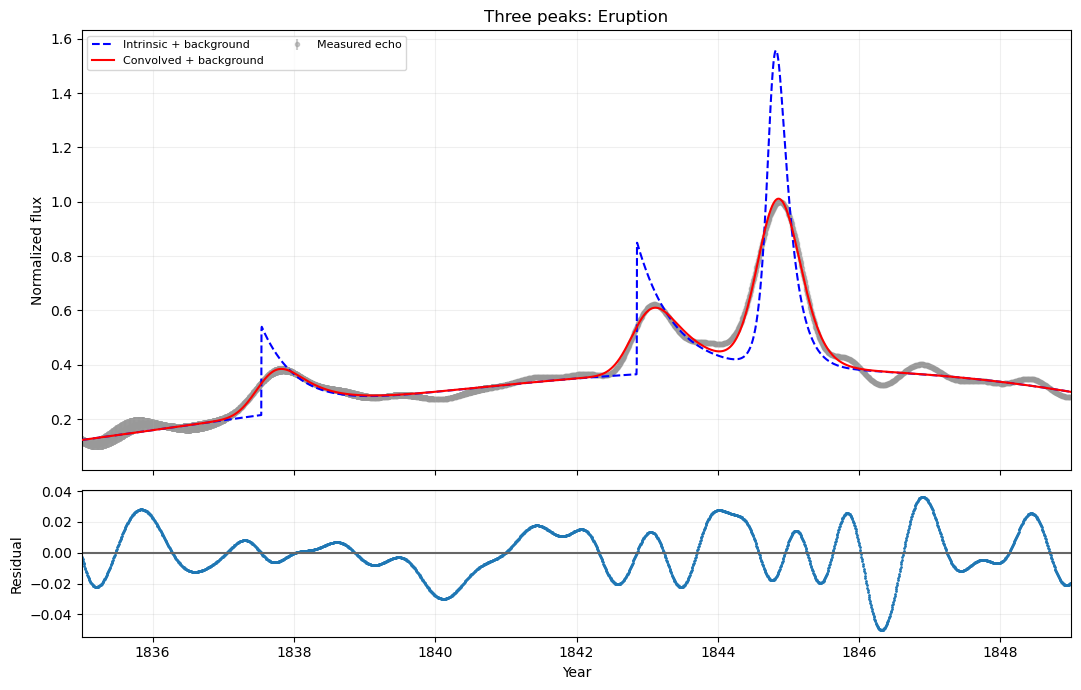

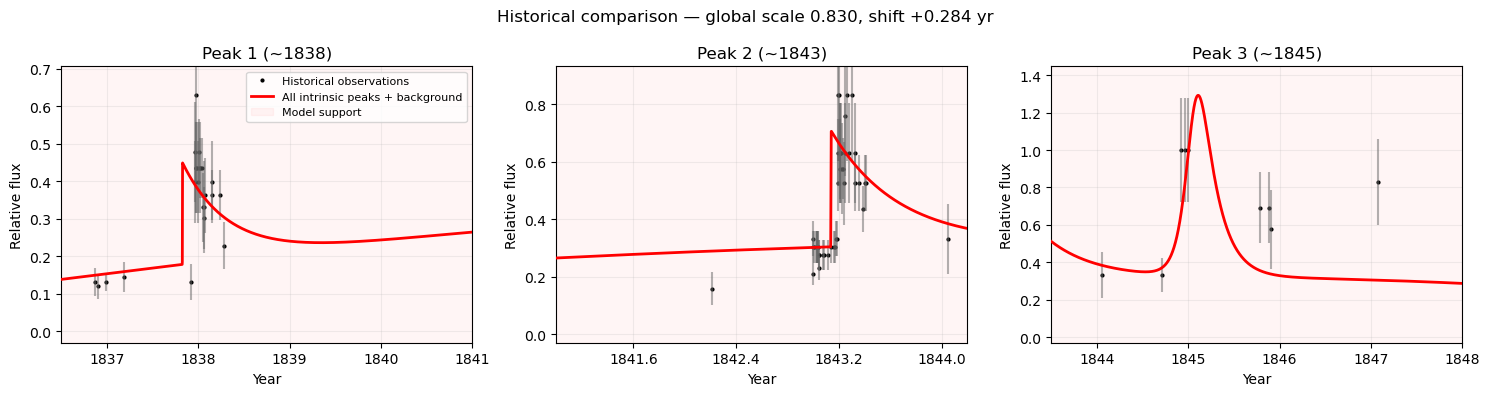

In [6]:
hist=pd.read_csv(BASE/'historical.txt',sep=r'\s+',header=None,comment='#')
ht=pd.to_numeric(hist.iloc[:,1],errors='coerce').to_numpy();hm=pd.to_numeric(hist.iloc[:,2],errors='coerce').to_numpy()
he=pd.to_numeric(hist.iloc[:,3],errors='coerce').to_numpy() if hist.shape[1]>3 else np.full(len(ht),np.nan)
valid=np.isfinite(ht)&np.isfinite(hm);ht,hm,he=ht[valid],hm[valid],he[valid]
hf=10**(-.4*(hm-np.min(hm)));herr=.4*np.log(10)*hf*he
# Fit just one shared scale and shift over the eruption interval; no per-peak alignment.
hmask=(ht>=1835)&(ht<=1849)
def alignment_residual(v):
    source_t=ht[hmask]-v[1]; supported=(source_t>=1835)&(source_t<=1849)
    prediction=np.zeros_like(source_t)
    prediction[supported]=v[0]*(intrinsic(source_t[supported],BASELINE)+background(source_t[supported]))
    return prediction-hf[hmask]
alignment=least_squares(alignment_residual,[.8,.3],bounds=([.01,-1],[3,1]))
ALIGN_SCALE,ALIGN_SHIFT=alignment.x
print('Illustrative least-squares global alignment (unweighted):',ALIGN_SCALE,ALIGN_SHIFT)
def plot_history(p,scale=1.,shift=0.,view='Eruption'):
    x=np.linspace(1835,1849,10000);xp=x+shift;yp=scale*(intrinsic(x,p)+background(x))
    if view=='Three peaks':
        fig,axes=plt.subplots(1,3,figsize=(15,4)); windows=[WINDOWS[k] for k in ['Peak 1','Peak 2','Peak 3']]
    else:
        fig,ax=plt.subplots(figsize=(11,4));axes=[ax]; windows=[(float(ht.min()),float(ht.max())) if view=='Full history' else WINDOWS[view]]
    for ax,window in zip(axes,windows):
        mask=(ht>=window[0])&(ht<=window[1]); ax.plot(ht[mask],hf[mask],'k.',ms=4,label='Historical observations')
        good=mask & np.isfinite(herr)&(herr>0)
        ax.errorbar(ht[good],hf[good],yerr=herr[good],fmt='none',ecolor='.4',alpha=.5)
        ax.plot(xp,yp,'r',lw=2,zorder=10,label='All intrinsic peaks + background')
        ax.axvspan(xp[0],xp[-1],color='red',alpha=.04,label='Model support')
        ax.set(xlim=window,xlabel='Year',ylabel='Relative flux')
        from matplotlib.ticker import MaxNLocator
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.ticklabel_format(axis='x',style='plain',useOffset=False)
        if view=='Three peaks': ax.set_title(['Peak 1 (~1838)','Peak 2 (~1843)','Peak 3 (~1845)'][list(axes).index(ax)])
        shown=(xp>=window[0])&(xp<=window[1]); vals=np.r_[hf[mask],yp[shown]]
        if len(vals): ax.set_ylim(min(-.03,float(vals.min())-.03),max(.1,float(vals.max())*1.12))
    axes[0].legend(fontsize=8);fig.suptitle(f'Historical comparison — global scale {scale:.3f}, shift {shift:+.3f} yr');plt.tight_layout();plt.show();plt.close(fig)
# Shared parameters for both datasets; alignment is historical-only.
combined_controls=peak_controls()
combined_controls['sigma_gauss']=control(BASELINE[12],'sigma (yr)',0,1)
combined_controls['scale']=control(ALIGN_SCALE,'History scale',.01,3)
combined_controls['shift']=control(ALIGN_SHIFT,'History shift',-1,1)
combined_controls['echo_view']=widgets.Dropdown(options=list(WINDOWS),value='Eruption',description='Echo view')
combined_controls['history_view']=widgets.Dropdown(options=['Full history','Eruption','Three peaks','Peak 1','Peak 2','Peak 3'],value='Three peaks',description='History view')
combined_controls['individual']=widgets.Checkbox(value=False,description='Individual peaks')
def combined_callback(**kw):
    p=np.array([kw[n] for n in NAMES])
    plot_echo(p,kw['echo_view'],kw['individual'])
    plot_history(p,kw['scale'],kw['shift'],kw['history_view'])
combined_ui=widget_panel(combined_controls,combined_callback,{
    **dict(zip(NAMES,BASELINE)), 'scale':ALIGN_SCALE,'shift':ALIGN_SHIFT,
    'echo_view':'Eruption','history_view':'Three peaks','individual':False})
# Static snapshots for readers whose widget renderer is not active.
plot_echo(BASELINE,individual=False)
plot_history(BASELINE,ALIGN_SCALE,ALIGN_SHIFT,'Three peaks')

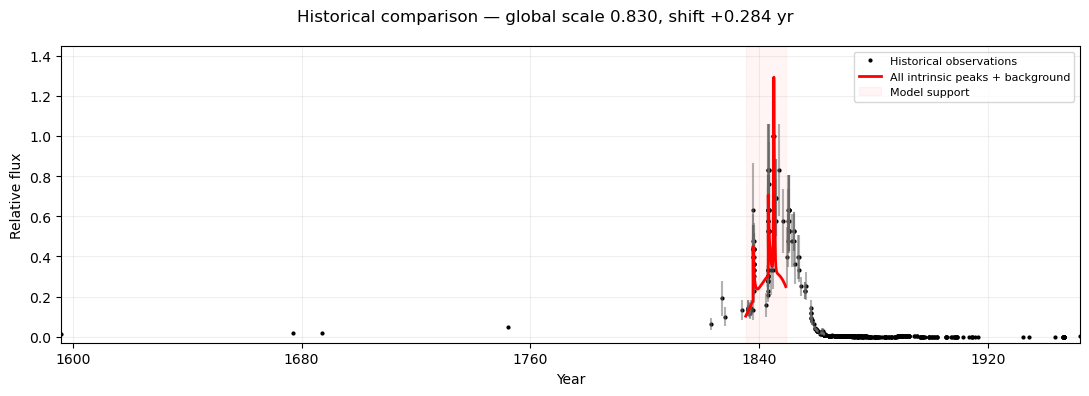

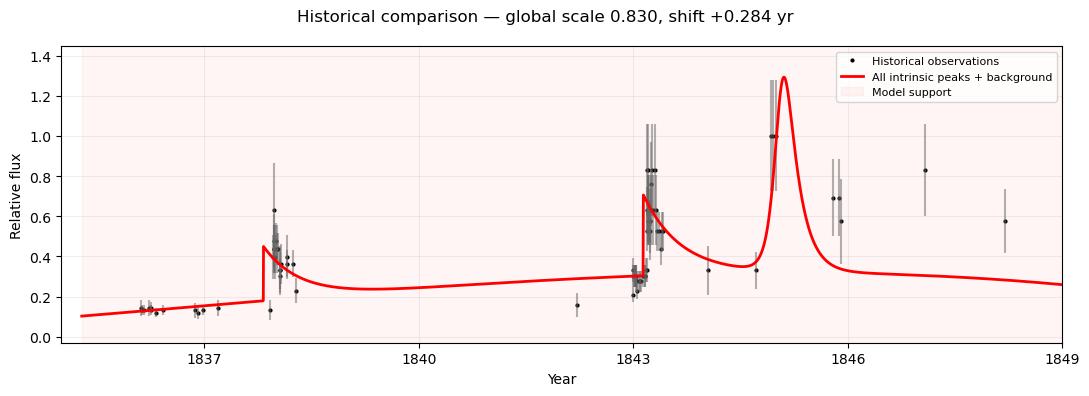

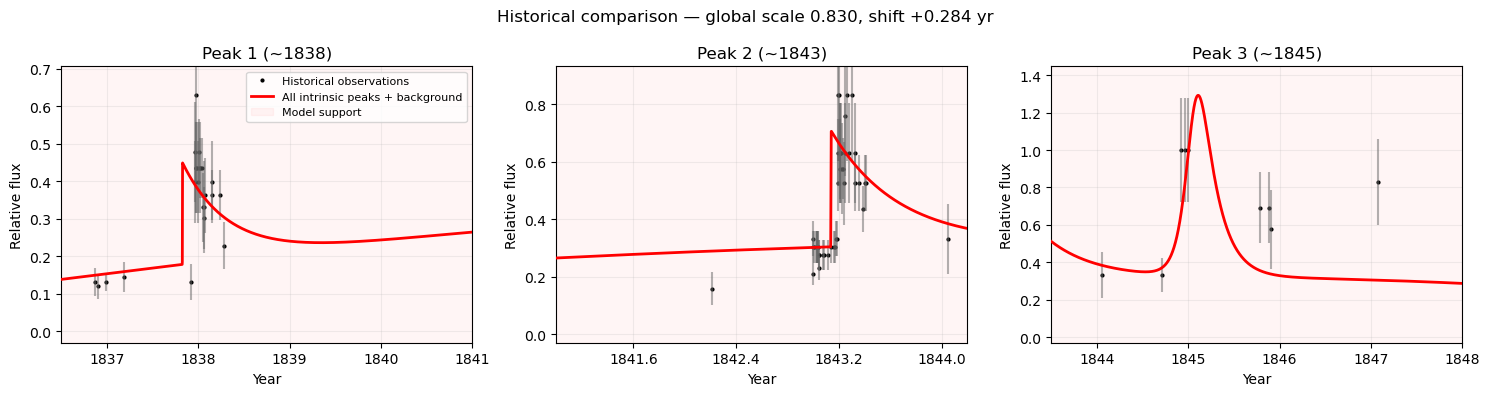

In [7]:
# Reproducible, static baseline comparisons (background restored in all views).
for view in ['Full history','Eruption','Three peaks']:
    plot_history(BASELINE,ALIGN_SCALE,ALIGN_SHIFT,view)

## 6. Full fitting workflow — expensive step is OFF
The bounds below reproduce Notebook 6. Set `RUN_FIT=True` only when ready to launch sampling. Exploration controls do not change these priors. The saved baseline remains unchanged; a new fit is written to a separate file. Re-run the subsequent result cells to inspect a new run.

The baseline was estimated with Notebook 6’s original convolution implementation. This notebook uses the corrected fixed-grid implementation, so a future new fit may move the optimum. No preliminary optimizer figure is shown.

In [8]:
RUN_FIT = False
NLIVE = 500
DLOGZ = .05
MAX_BATCH = 5
SEED = 42
LOWER=np.array([0,1837,.0001,.1,0,1841,.0001,.1,0,1844,.0001,.1,0.])
UPPER=np.array([2,1840,.003,.8,3,1843,.003,2,5,1847,.06,2,2.])
assert np.all(LOWER<UPPER)
def prior_transform(u): return LOWER+np.asarray(u)*(UPPER-LOWER)
def log_likelihood(p):
    if any(p[k+2]>=p[k+3] for k in (0,4,8)): return -np.inf
    residual=(yf-background(tf)-convolved(tf,p))/ef
    return -.5*np.sum(residual**2)
# No optimization or sampling is triggered by evaluating this configuration.
print('Sampling enabled:',RUN_FIT)
print('Reference log likelihood under corrected implementation:',log_likelihood(BASELINE))

Sampling enabled: False
Reference log likelihood under corrected implementation: -60961.16759168051


In [9]:
if RUN_FIT:
    import dynesty, pickle
    sampler=dynesty.DynamicNestedSampler(log_likelihood,prior_transform,ndim=13,
        bound='multi',sample='rwalk',nlive=NLIVE,rstate=np.random.default_rng(SEED))
    sampler.run_nested(dlogz_init=DLOGZ,nlive_init=NLIVE,nlive_batch=100,maxbatch=MAX_BATCH,print_progress=True)
    new_results=sampler.results
    with (BASE/'new_gaussian_fit.pkl').open('wb') as handle: pickle.dump(new_results,handle)
    np.savez_compressed(BASE/'new_posterior.npz',samples=new_results.samples,logwt=new_results.logwt,logz=new_results.logz,logl=new_results.logl)
else:
    print('Long fit skipped. Loading existing posterior in the next section.')

Long fit skipped. Loading existing posterior in the next section.


## 7. Final reference result and uncertainties
The table uses weighted posterior quantiles; the overlay uses the maximum stored likelihood sample. The shaded band is the 16th–84th percentile **model-curve uncertainty**, conditional on the old fit and fixed background; it does not include observation noise or background uncertainty. It is not a refit using the corrected convolution.

A narrow band does not establish model adequacy: inspect the residuals and prior boundaries.

,parameter,q16,median,q84
0,A1,0.315915,0.323855,0.331359
1,t0_1,1837.524871,1837.532709,1837.540196
2,tau_rise_1,0.000553,0.001488,0.002496
3,tau_fall_1,0.509153,0.524774,0.541450
4,A2,0.482785,0.484507,0.487599
5,t0_2,1842.847154,1842.848567,1842.851740
6,tau_rise_2,0.000217,0.000480,0.000876
7,tau_fall_2,0.525965,0.530045,0.532581
8,A3,2.172512,2.176944,2.183261
9,t0_3,1844.773545,1844.774511,1844.777835


Near a prior boundary: ['tau_rise_3']


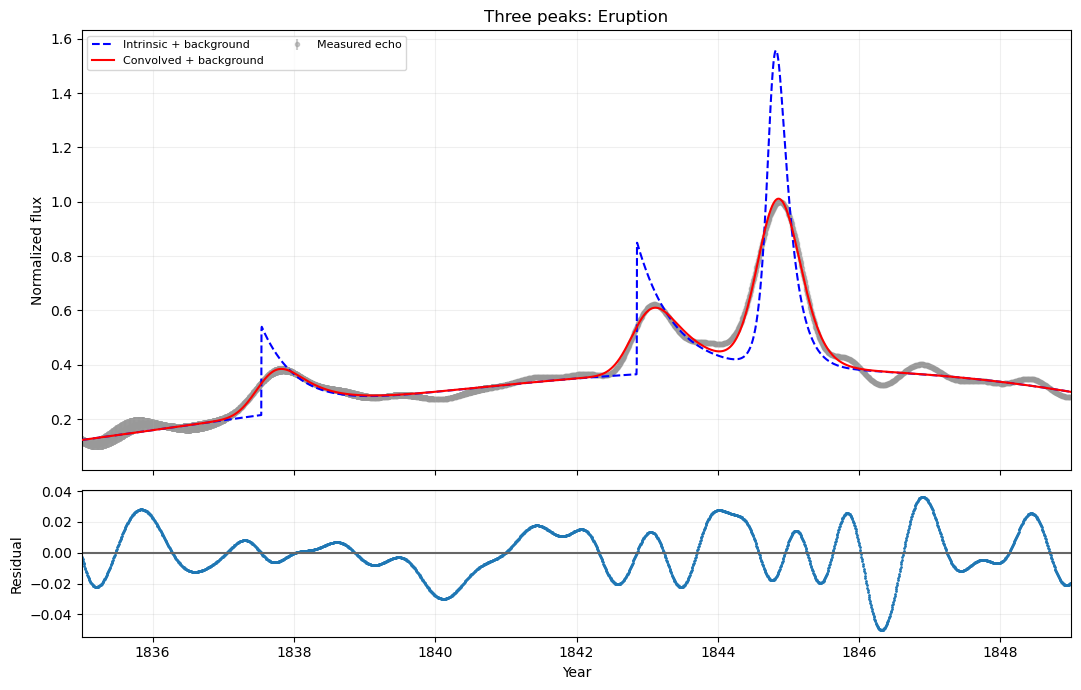

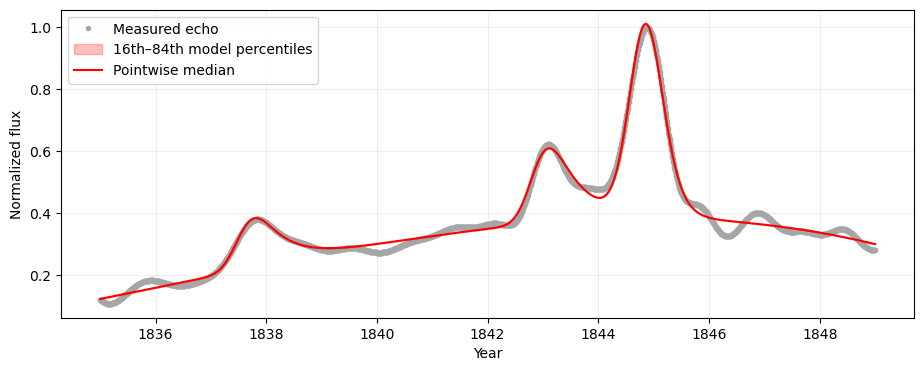

Reduced chi-square (corrected grid, fixed background): 55.85081776608384


In [10]:
posterior_path=BASE/('new_posterior.npz' if RUN_FIT else 'posterior.npz')
post=np.load(posterior_path); samples=post['samples'];weights=np.exp(post['logwt']-np.max(post['logwt']));weights/=weights.sum()
reference=samples[np.argmax(post['logl'])]
def weighted_quantile(v,q):
    order=np.argsort(v); return np.interp(q,np.cumsum(weights[order]),v[order])
quant=np.array([weighted_quantile(samples[:,i],[.16,.5,.84]) for i in range(13)])
display(pd.DataFrame({'parameter':NAMES,'q16':quant[:,0],'median':quant[:,1],'q84':quant[:,2]}))
near=(quant[:,1]-LOWER)/(UPPER-LOWER)
print('Near a prior boundary:',[n for n,v in zip(NAMES,near) if v<.01 or v>.99])
plot_echo(reference,individual=False)
rng=np.random.default_rng(SEED); draws=samples[rng.choice(len(samples),100,p=weights)]
x=np.linspace(1835,1849,1800);curves=np.array([convolved(x,p)+background(x) for p in draws]);q=np.percentile(curves,[16,50,84],axis=0)
fig,ax=plt.subplots(figsize=(11,4));ax.plot(tf,yf,'.',color='.65',zorder=1,label='Measured echo');ax.fill_between(x,q[0],q[2],color='red',alpha=.25,label='16th–84th model percentiles');ax.plot(x,q[1],'r',zorder=10,label='Pointwise median');ax.legend();ax.set(xlabel='Year',ylabel='Normalized flux');plt.show();plt.close(fig)
print('Reduced chi-square (corrected grid, fixed background):',-2*log_likelihood(reference)/(len(tf)-13))

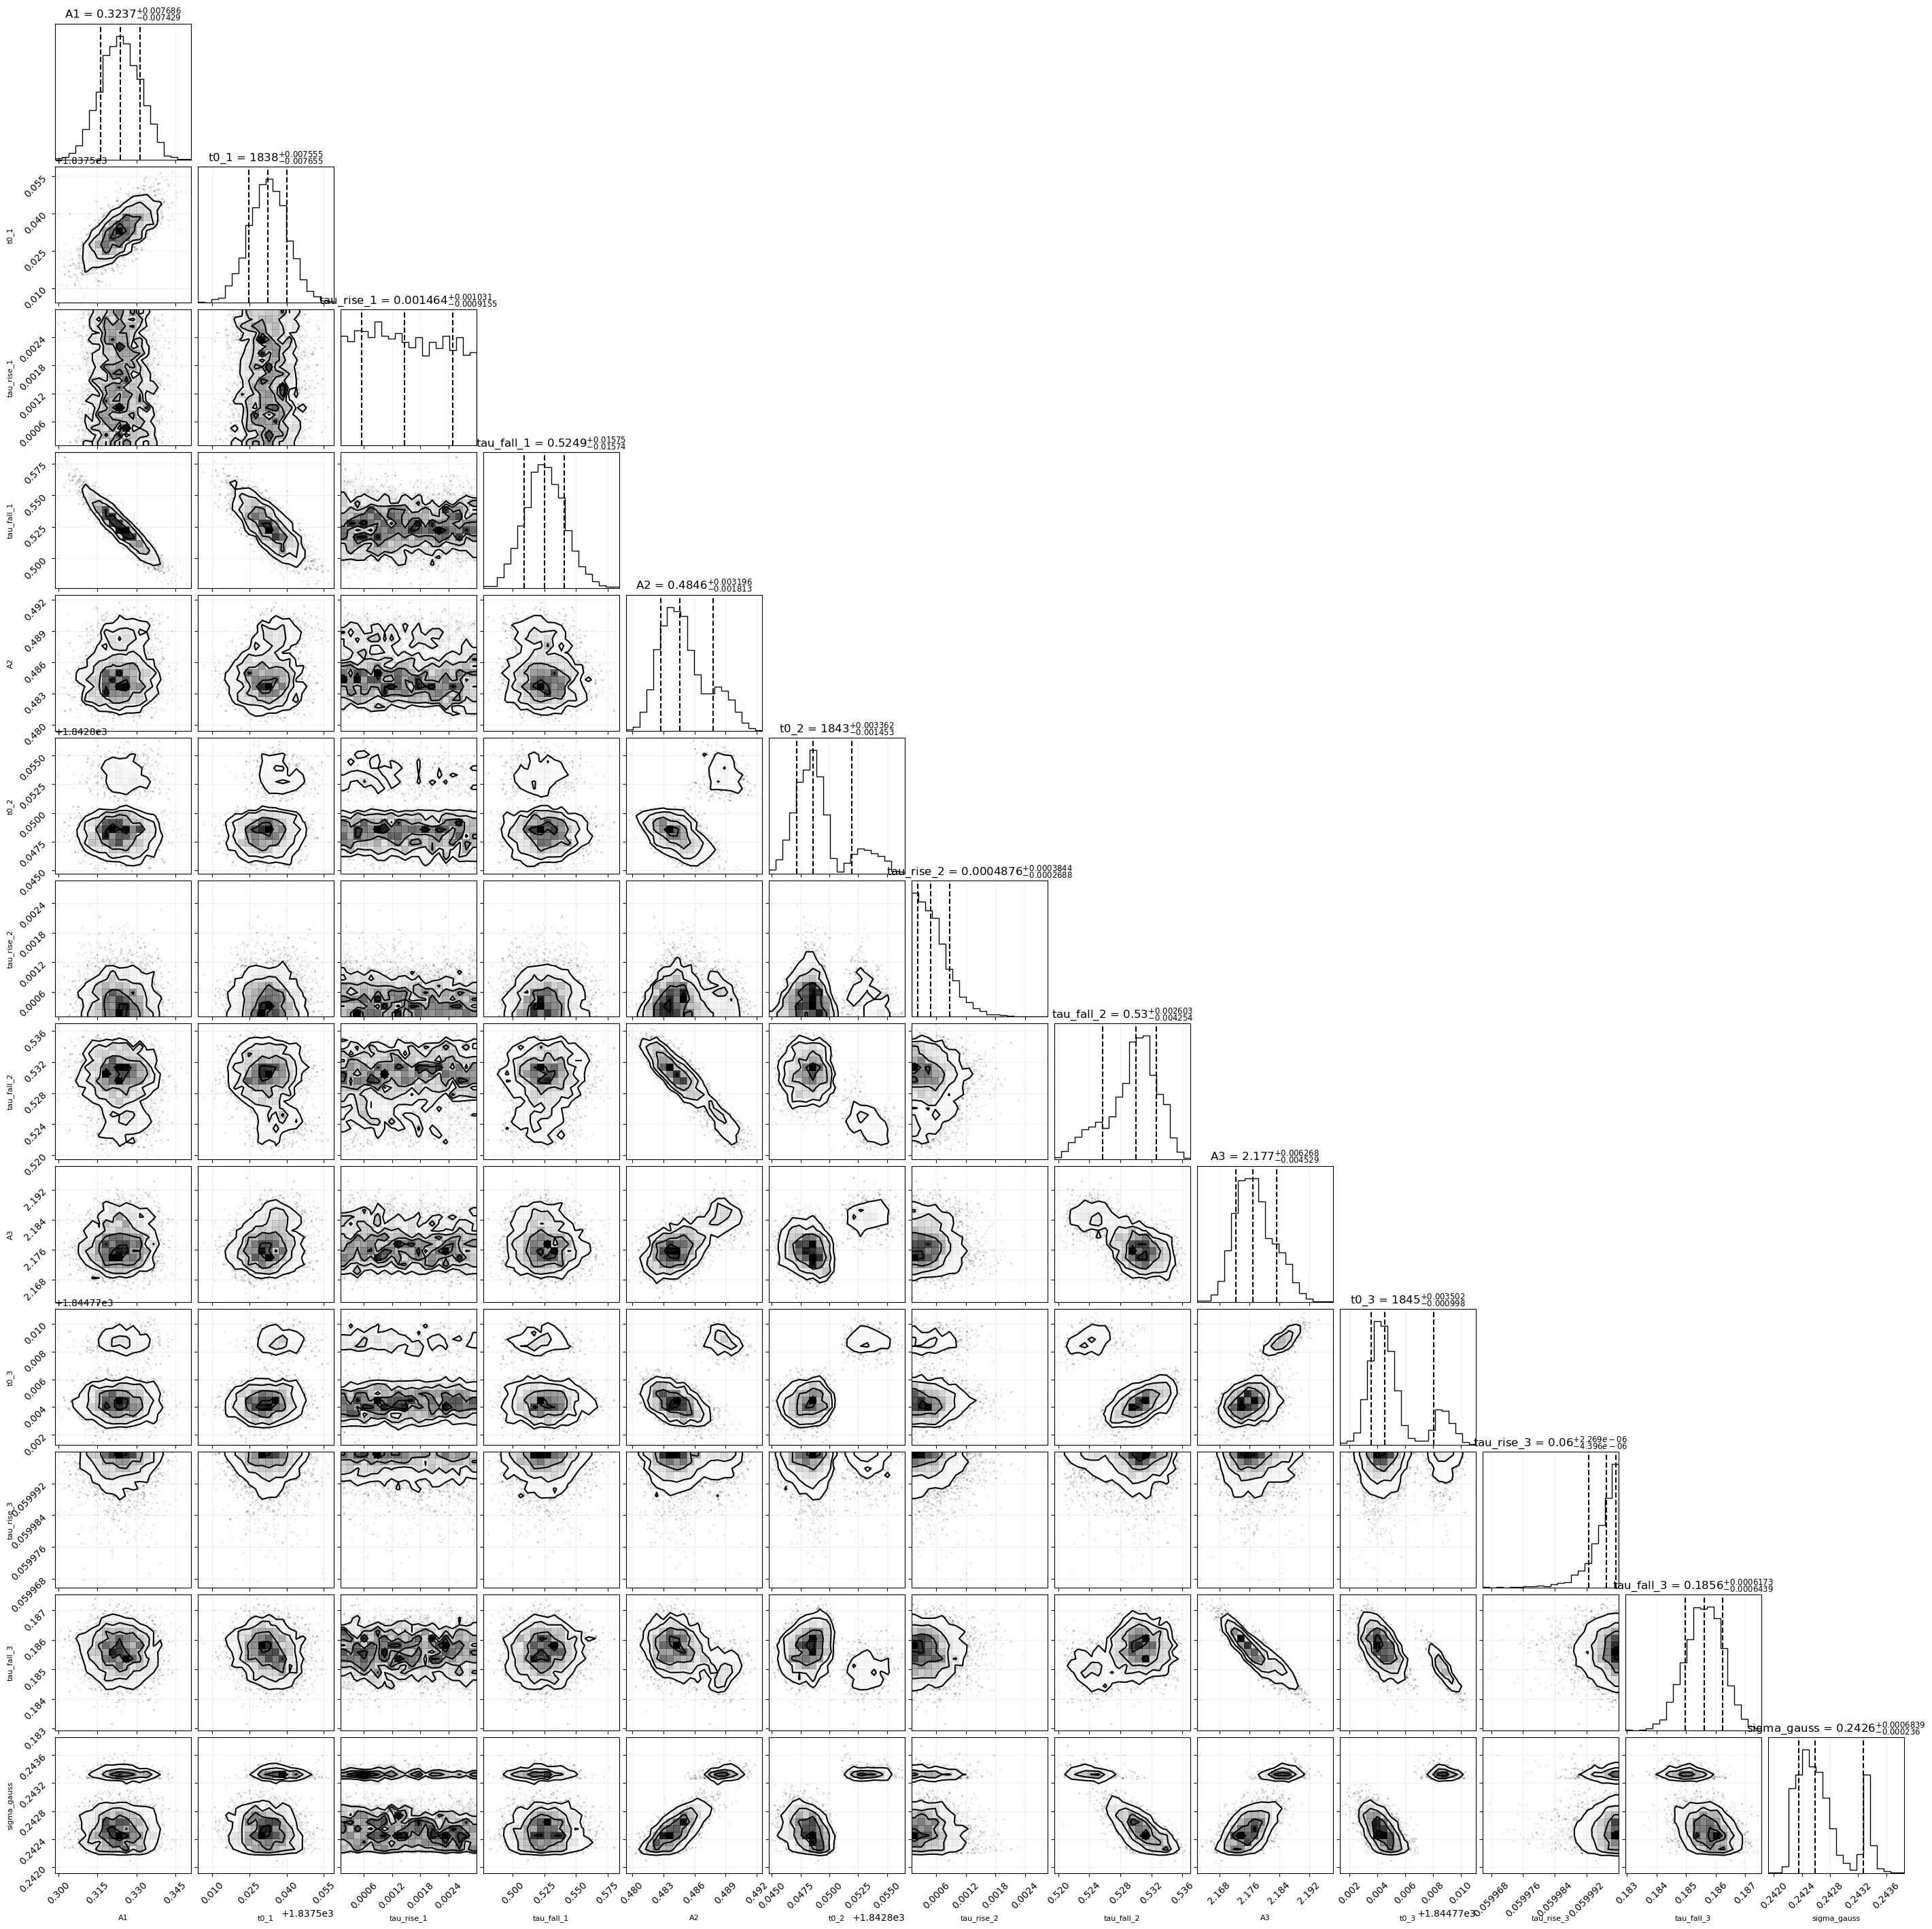

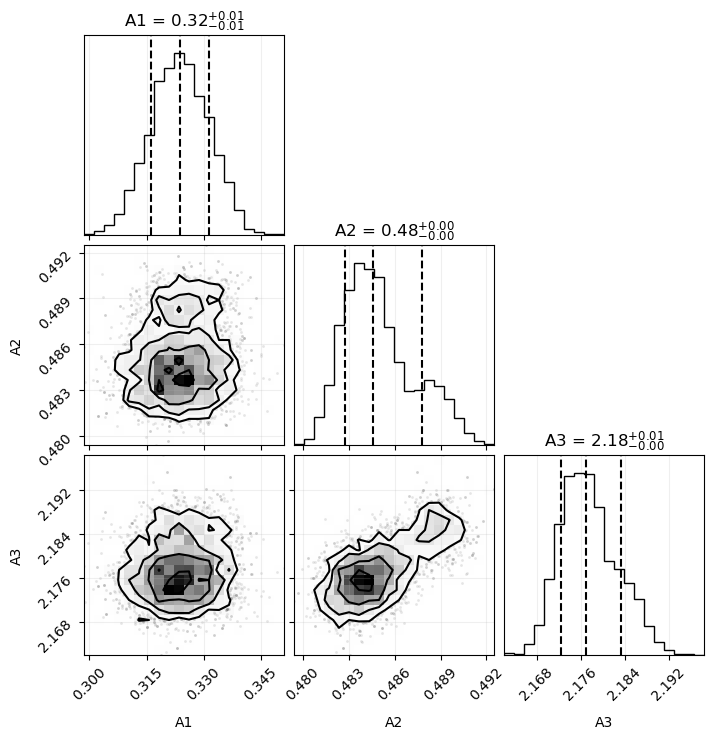

In [11]:
import corner
# A reproducible subset keeps the large corner figure responsive.
equal_samples=samples[rng.choice(len(samples),4000,p=weights)]
fig=corner.corner(equal_samples,labels=NAMES,quantiles=[.16,.5,.84],show_titles=True,title_fmt='.4g',label_kwargs={'fontsize':8})
plt.show();plt.close(fig)
fig=corner.corner(equal_samples[:,[0,4,8]],labels=['A1','A2','A3'],quantiles=[.16,.5,.84],show_titles=True)
plt.show();plt.close(fig)

### Sampling diagnostics
Load only the existing trusted local Dynesty result (pickle files must not come from untrusted sources). If this notebook folder is moved without the parent result file, the portable posterior and all other sections still work. Trace plots show nested-sampling evolution and marginal distributions; they do not alone prove convergence.

In [12]:
import pickle
from dynesty import plotting as dyplot
result_path=BASE/('new_gaussian_fit.pkl' if RUN_FIT else 'original_sampler_not_bundled.pkl')
if result_path.exists():
    with result_path.open('rb') as handle: diagnostics=pickle.load(handle)
    fig,axes=dyplot.runplot(diagnostics,logplot=True);fig.suptitle('Nested sampling diagnostics (log evidence scale)');plt.show();plt.close(fig)
    fig,axes=dyplot.traceplot(diagnostics,labels=NAMES,show_titles=True);plt.show();plt.close(fig)
else:
    print('Detailed sampler result not bundled. Posterior summaries above remain available.')

Detailed sampler result not bundled. Posterior summaries above remain available.
